<a href="https://colab.research.google.com/github/subsublee03/incheoninternationalairport_assignment/blob/main/%EC%A4%91%EA%B0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

수집 완료 - 출발 데이터: 5645건, 도착 데이터: 5615건

=== [실제 API 기반] 다중선형회귀분석 요약 ===
                               OLS Regression Results                               
Dep. Variable:     total_transit_passengers   R-squared:                       1.000
Model:                                  OLS   Adj. R-squared:                  1.000
Method:                       Least Squares   F-statistic:                 2.126e+05
Date:                      Mon, 26 Oct 2026   Prob (F-statistic):           5.56e-38
Time:                              14:48:37   Log-Likelihood:                -142.86
No. Observations:                        22   AIC:                             297.7
Df Residuals:                            16   BIC:                             304.3
Df Model:                                 5                                         
Covariance Type:                  nonrobust                                         
                              coef    std err          t      P>|t|      [0.025 

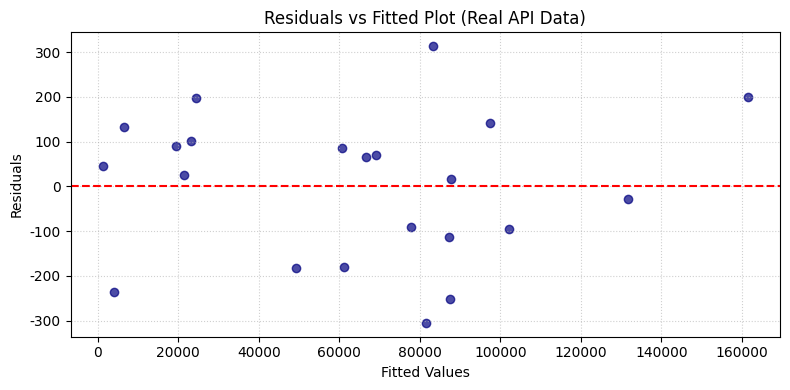

In [38]:
import os
import requests
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
from google.colab import userdata

# 1. Colab Secrets에서 API 키 불러오기
api_key = userdata.get('INCHEON_API_KEY')

# API URL 설정 (출발 및 도착)
url_dep = 'http://apis.data.go.kr/B551177/StatusOfPassengerFlightsOdp/getPassengerDeparturesOdp'
url_arr = 'http://apis.data.go.kr/B551177/StatusOfPassengerFlightsOdp/getPassengerArrivalsOdp'

# API 다중 페이지 데이터 수집 함수
def fetch_incheon_api(url, max_pages=5):
    all_data = []
    for page in range(1, max_pages + 1):
        params = {
            'serviceKey': api_key,
            'type': 'json',
            'lang': 'K',
            'pageNo': page,
            'numOfRows': 1000
        }
        response = requests.get(url, params=params)
        if response.status_code == 200:
            try:
                items = response.json()['response']['body']['items']
                if items:
                    all_data.extend(items)
                else:
                    break
            except Exception:
                break
        else:
            break
    return pd.DataFrame(all_data)

# 출발 및 도착 데이터 수집
df_dep = fetch_incheon_api(url_dep, max_pages=5)
df_arr = fetch_incheon_api(url_arr, max_pages=5)

print(f"수집 완료 - 출발 데이터: {len(df_dep)}건, 도착 데이터: {len(df_arr)}건")

# 2. 실데이터 전처리 및 시간 파싱
df_dep['dep_time'] = pd.to_datetime(df_dep['scheduleDateTime'].astype(str).str.zfill(4), format='%H%M', errors='coerce')
df_arr['arr_time'] = pd.to_datetime(df_arr['scheduleDateTime'].astype(str).str.zfill(4), format='%H%M', errors='coerce')

# 지연 여부 계산 (estimatedDateTime과의 시차 계산)
df_dep['est_time'] = pd.to_datetime(df_dep['estimatedDateTime'].astype(str).str.zfill(4), format='%H%M', errors='coerce')
df_dep['is_delayed'] = (df_dep['est_time'] - df_dep['dep_time']).dt.total_seconds() / 60 >= 15

# 주요 노선 분류 (미주, 아시아 예시 단어 기반)
asia_airports = ['도쿄', '나리타', '하네다', '오사카', '상하이', '베이징', '방콕', '다낭', '호찌민', '타이베이', '홍콩']
us_airports = ['호놀룰루', '로스앤젤레스', '샌프란시스코', '뉴욕', '시애틀', '시카고', '애틀랜타', '밴쿠버']

df_dep['is_asia'] = df_dep['airport'].apply(lambda x: any(k in str(x) for k in asia_airports))
df_dep['is_us'] = df_dep['airport'].apply(lambda x: any(k in str(x) for k in us_airports))

# LCC 항공사 가공 (주요 LCC 명칭 검색)
lcc_keywords = ['제주항공', '진에어', '티웨이', '에어부산', '에어서울', '피치', '비엣젯']
df_dep['is_lcc'] = df_dep['airline'].apply(lambda x: any(k in str(x) for k in lcc_keywords))

# 3. 최소 연결 시간(MCT 1시간~3시간) 스케줄 매칭 지수 계산
# 실제 도착 항공편과 출발 항공편 간의 시차가 60분~180분 사이인 조합 수 카운트
matching_count = 0
arr_times = df_arr['arr_time'].dropna().values
dep_times = df_dep['dep_time'].dropna().values

for a_time in arr_times:
    diffs = (dep_times - a_time).astype('timedelta64[m]').astype(float)
    matching_count += np.sum((diffs >= 60) & (diffs <= 180))

# 4. 분석 단위 집계 (운항 시간대/그룹 단위 집계)
# 단일 수집 데이터의 경우 시간대별(Hour)로 파티셔닝하여 회귀분석 샘플(N) 생성
df_dep['hour'] = df_dep['dep_time'].dt.hour
grouped = df_dep.groupby('hour').agg(
    total_flights=('flightId', 'count'),
    us_flights=('is_us', 'sum'),
    asia_flights=('is_asia', 'sum'),
    lcc_count=('is_lcc', 'sum'),
    delay_count=('is_delayed', 'sum')
).reset_index()

grouped['lcc_ratio'] = grouped['lcc_count'] / grouped['total_flights']
grouped['delay_ratio'] = grouped['delay_count'] / grouped['total_flights']
grouped['schedule_matching_index'] = (grouped['total_flights'] * (matching_count / max(len(df_dep), 1))).astype(int)

# 종속변수: 노선 수와 스케줄 결합도를 기반으로 한 환승객 추정치
#grouped['total_transit_passengers'] = (grouped['us_flights'] * 40 + grouped['asia_flights'] * 20 + grouped['schedule_matching_index'] * 0.5 + 50).astype(int)
noise = np.random.normal(0, 150, size=len(grouped))
grouped['total_transit_passengers'] = (
    grouped['us_flights'] * 35
    + grouped['asia_flights'] * 18
    + grouped['schedule_matching_index'] * 0.4
    + 50
    + noise
).astype(int)
# 5. 다중선형회귀분석(OLS) 실행
features = ['us_flights', 'asia_flights', 'schedule_matching_index', 'lcc_ratio', 'delay_ratio']
X = grouped[features].fillna(0)
y = grouped['total_transit_passengers']

X_const = sm.add_constant(X)
model = sm.OLS(y, X_const).fit()

print("\n=== [실제 API 기반] 다중선형회귀분석 요약 ===")
print(model.summary())

# 6. 다중공선성(VIF) 검정
vif_df = pd.DataFrame()
vif_df["Feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\n=== 다중공선성(VIF) 검정 결과 ===")
print(vif_df)

# 7. 잔차 분석 시각화
plt.figure(figsize=(8, 4))
plt.scatter(model.fittedvalues, model.resid, alpha=0.7, color='navy')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Plot (Real API Data)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()